# 03 Problem framing, split and baselines
**Forecast origin:** midnight. For day D we know everything up to 23:00 of D-1, so every demand feature must be at least 24 hours old.

**Baselines:** same hour yesterday (lag 24), same hour last week (lag 168), and a *day-type* naive (Tue-Fri copy yesterday, Mon/Sat/Sun copy last week).
**Validation:** one 8-week holdout, then six walk-forward folds of 4 weeks each.

In [1]:
import pandas as pd, numpy as np
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

h = pd.read_csv("../data/processed/hourly.csv", index_col=0, parse_dates=True)
y = h["total"]

# Forecast origin: midnight. For day D we know everything up to 23:00 of D-1,
# so the smallest safe lag is 24 hours.
TEST_DAYS = 56
split = y.index[-24 * TEST_DAYS]
print("train:", y.index[0], "->", y.index[y.index < split][-1])
print("test :", split, "->", y.index[-1])

pred = pd.DataFrame({"actual": y})
pred["naive_24"]  = y.shift(24)    # same hour yesterday
pred["naive_168"] = y.shift(168)   # same hour last week
# day-type naive: Tue-Fri copy yesterday; Mon/Sat/Sun copy last week
pred["daytype"] = np.where(y.index.day_of_week.isin([1, 2, 3, 4]),
                           pred["naive_24"], pred["naive_168"])

def mape(a, f):
    return (np.abs(a - f) / np.abs(a)).mean() * 100

test = pred.loc[split:].dropna()
rows = []
for c in ["naive_24", "naive_168", "daytype"]:
    rows.append({"model": c,
                 "MAE": mean_absolute_error(test["actual"], test[c]),
                 "RMSE": root_mean_squared_error(test["actual"], test[c]),
                 "MAPE_%": mape(test["actual"], test[c])})
print(pd.DataFrame(rows).set_index("model").round(2))

train: 2017-01-01 00:00:00 -> 2017-11-04 23:00:00
test : 2017-11-05 00:00:00 -> 2017-12-30 23:00:00
               MAE     RMSE  MAPE_%
model                              
naive_24   2161.87  3286.48    3.47
naive_168  2086.13  2933.41    3.30
daytype    1728.02  2568.96    2.76


In [2]:
from sklearn.model_selection import TimeSeriesSplit

# 6 folds, each tests on 4 weeks; training window grows each fold
tscv = TimeSeriesSplit(n_splits=6, test_size=24 * 28)
rows = []
for i, (tr, te) in enumerate(tscv.split(y), start=1):
    t = pred.iloc[te]
    rows.append({"fold": i,
                 "test_start": t.index[0].date(),
                 "test_end": t.index[-1].date(),
                 "train_days": len(tr) // 24,
                 "MAE_naive168": mean_absolute_error(t["actual"], t["naive_168"]),
                 "MAE_daytype": mean_absolute_error(t["actual"], t["daytype"]),
                 "MAPE_daytype_%": mape(t["actual"], t["daytype"])})
folds = pd.DataFrame(rows).set_index("fold")
print(folds.round(2))

      test_start    test_end  train_days  MAE_naive168  MAE_daytype  \
fold                                                                  
1     2017-07-16  2017-08-12         196       3635.36      2306.56   
2     2017-08-13  2017-09-09         224       6912.68      4081.74   
3     2017-09-10  2017-10-07         252       2345.47      1607.71   
4     2017-10-08  2017-11-04         280       1458.37      1199.60   
5     2017-11-05  2017-12-02         308       2590.69      2175.02   
6     2017-12-03  2017-12-30         336       1581.57      1281.02   

      MAPE_daytype_%  
fold                  
1               2.55  
2               5.72  
3               2.35  
4               1.84  
5               3.47  
6               2.04  


MAE overall: 1728.0
MAE at peaks (top 10% load): 1376.2


<Axes: title={'center': 'Daytype baseline: MAE by hour'}, xlabel='DateTime'>

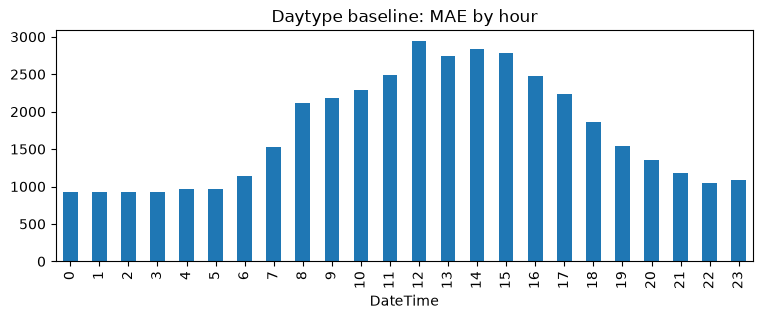

In [3]:
# Error slices on the Nov-Dec holdout (daytype baseline)
test = pred.loc[split:].copy()
test["err"] = (test["actual"] - test["daytype"]).abs()

print("MAE overall:", round(test["err"].mean(), 1))
peak = test["actual"] >= test["actual"].quantile(0.90)
print("MAE at peaks (top 10% load):", round(test.loc[peak, "err"].mean(), 1))

test.groupby(test.index.hour)["err"].mean().plot(
    kind="bar", figsize=(9, 3), title="Daytype baseline: MAE by hour")

In [4]:
folds_df = pd.concat([pred.iloc[te] for _, te in tscv.split(y)])
folds_df["err"] = (folds_df["actual"] - folds_df["daytype"]).abs()

thr = y.quantile(0.90)   # full-year threshold: only labels a reporting slice, trains nothing
is_peak = folds_df["actual"] >= thr
print("MAE, all folds:", round(folds_df["err"].mean(), 1))
print("MAE, peaks    :", round(folds_df.loc[is_peak, "err"].mean(), 1), "| peak hours:", is_peak.sum())

print(folds_df.groupby(folds_df.index.hour)["err"].mean().sort_values(ascending=False).head(5).round(0))

MAE, all folds: 2108.6
MAE, peaks    : 2508.7 | peak hours: 465
DateTime
12    2829.0
13    2656.0
14    2637.0
15    2602.0
10    2566.0
Name: err, dtype: float64


In [5]:
f2 = pred.loc["2017-08-13":"2017-09-09"].copy()
f2["err"] = (f2["actual"] - f2["daytype"]).abs()
d = f2.resample("D").agg(load=("actual", "mean"), err=("err", "mean"))
d["temp"] = h["Temperature"].resample("D").mean()
d["dow"] = d.index.day_name().str[:3]
print(d.round(1).sort_values("err", ascending=False).head(8))

               load      err  temp  dow
DateTime                               
2017-09-02  64747.9  16475.0  22.8  Sat
2017-09-03  65739.7  12498.2  22.5  Sun
2017-09-04  66774.4  10903.2  22.1  Mon
2017-09-01  61623.6   8164.4  23.7  Fri
2017-08-26  81222.9   6939.6  24.6  Sat
2017-08-14  86208.8   6783.4  23.6  Mon
2017-08-28  77677.7   6655.8  24.8  Mon
2017-09-09  70097.4   5987.9  23.5  Sat


## Conclusion
- Single holdout (Nov 5 - Dec 30), MAE: naive_24 = 2,162, naive_168 = 2,086, **day-type = 1,728**. The day-type naive is the baseline to beat.
- Walk-forward MAE of the day-type baseline per fold: 2,307 / 4,082 / 1,608 / 1,200 / 2,175 / 1,281 (mean 2,109). The single holdout hid this spread.
- Fold 2 (Aug 13 - Sep 9) is hardest. Its error is concentrated on Sep 1-4, which fits Eid al-Adha (Sep 1, 2017). Load dropped about 25k at the same temperature, so weather does not explain it. The data cannot prove the cause.
- Peaks have higher error than average across folds (2,509 vs 2,109); the worst hours are 10 to 15.
- **Success rule set here:** the model must beat the day-type baseline MAE in every fold and not be worse at peaks.